In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

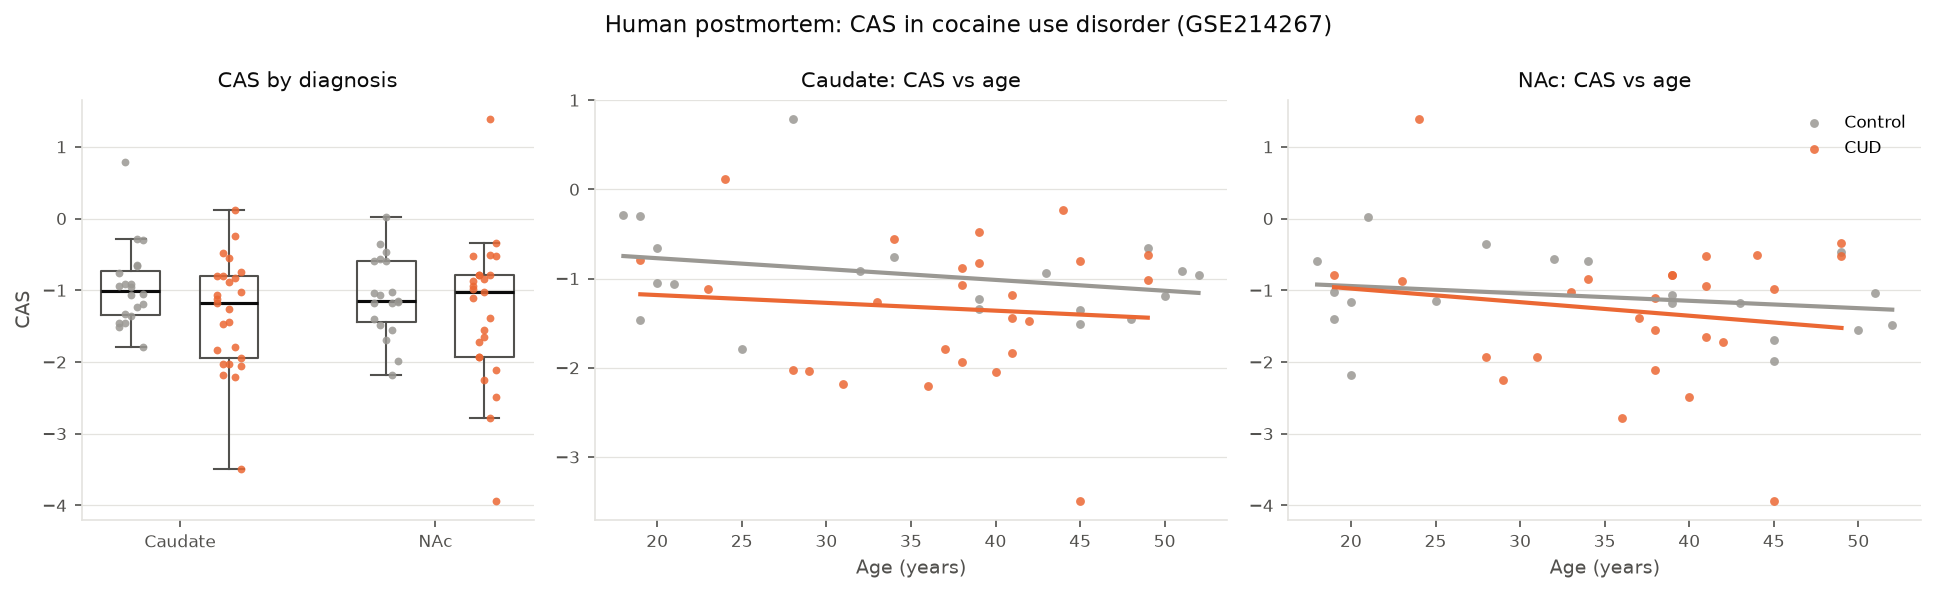

In [3]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
stats = pd.read_csv(tables / "table_human_cud_stats.csv")
models = pd.read_csv(tables / "table_human_cud_models.csv")
ages = pd.read_csv(tables / "table_human_age_control.csv")
scores = pd.read_csv(tables / "human_cas_scores.csv")
display(Image(figs / "fig7_human_cud.png"))

In [4]:
stats[["run", "region", "n_treat", "n_ctrl", "g", "g_ci_low", "g_ci_high", "welch_fdr", "perm_p"]].round(3)

,run,region,n_treat,n_ctrl,g,g_ci_low,g_ci_high,welch_fdr,perm_p
0,all,Caudate,25,20,-0.537,-1.061,-0.016,0.132,0.126
1,all,NAc,25,19,-0.242,-0.836,0.296,0.390,0.419
2,excl_flagged,Caudate,24,17,-0.318,-0.909,0.235,0.552,0.368
3,excl_flagged,NAc,17,18,-0.150,-0.800,0.535,0.655,0.718


In [5]:
models[["run", "model", "n", "coef_cud", "ci_low", "ci_high", "p", "age_coef", "age_p"]].round(3)

,run,model,n,coef_cud,ci_low,ci_high,p,age_coef,age_p
0,all,OLS Caudate,45,-0.351,-0.769,0.067,0.097,-0.010,0.367
1,all,OLS NAc,44,-0.174,-0.716,0.368,0.521,-0.014,0.326
2,all,"Mixed (donor random intercept), CUD effect in ...",89,-0.350,-0.810,0.110,0.136,-0.012,0.295
3,excl_flagged,OLS Caudate,41,-0.194,-0.569,0.181,0.302,-0.001,0.959
4,excl_flagged,OLS NAc,35,-0.076,-0.527,0.375,0.733,0.006,0.598
5,excl_flagged,"Mixed (donor random intercept), CUD effect in ...",76,-0.122,-0.502,0.258,0.530,0.000,0.995


In [6]:
ages.round(3)

,region,subset,n,spearman_rho,p,age_range
0,Caudate,all donors,45,-0.113,0.459,18-52
1,Caudate,controls only,20,-0.227,0.335,18-52
2,NAc,all donors,44,-0.078,0.616,18-52
3,NAc,controls only,19,-0.243,0.315,18-52


Spearman r: 0.72


Text(0.5, 1.0, 'CAS: same donor, two regions')

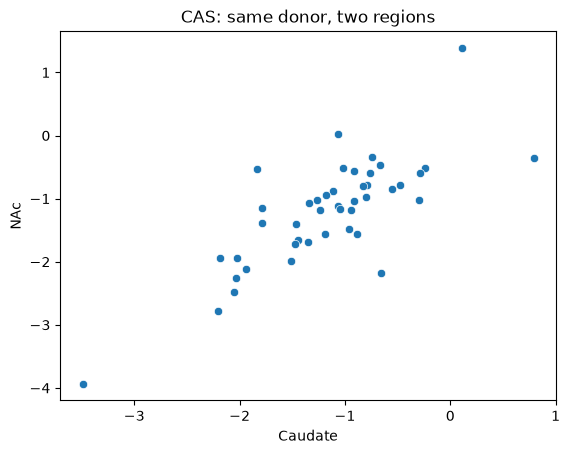

In [7]:
wide = scores.pivot(index="subject_id", columns="region", values="cas").dropna()
print("Spearman r:", round(wide.corr(method="spearman").iloc[0, 1], 2))
sns.scatterplot(data=wide, x="Caudate", y="NAc")
plt.title("CAS: same donor, two regions")

Text(0.5, 1.0, 'Human NAc: CAS by plate column')

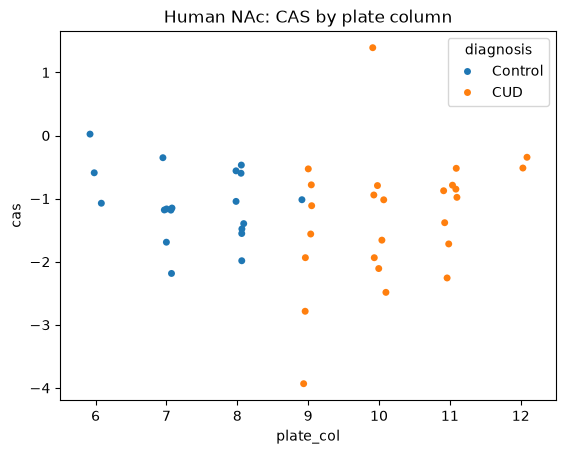

In [8]:
nac = scores.query("region == 'NAc'").copy()
nac["plate_col"] = nac["well"].str[1:].astype(int)
sns.stripplot(data=nac, x="plate_col", y="cas", hue="diagnosis")
plt.title("Human NAc: CAS by plate column")